In [1]:
from datetime import date, timedelta
from dateutil.rrule import rrule, DAILY

import itertools

import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
%matplotlib inline

import numpy as np
import pandas as pd

import scipy.stats as ss
from sklearn import linear_model
import statsmodels.api as sm

import warnings

In [2]:
df_vitals_combined = pd.read_csv('vitals_combined_interpolated.csv')

In [ ]:
df_vitals_combined_SBP = df_vitals_combined[['patient_uuid','reading_date','batch','SBP']]

df_vitals_combined_HR = df_vitals_combined[['patient_uuid','reading_date','batch','HR']]

In [3]:
# The below two lines are for running it only for the max batch. We are now running it on all batches. 
#idx = df_vitals.groupby(['patient_uuid'])['batch'].transform(max) == df_vitals['batch']
#df_vitals = df_vitals[idx]


df_vitals_82591262 = df_vitals_combined_SBP[df_vitals_combined_SBP['patient_uuid'] == 82591262]

for batch in df_vitals_82591262['batch'].unique():
    df_vitals_82591262_batch = df_vitals_82591262[df_vitals_82591262['batch'] == batch]
    
    df_vitals = df_vitals_82591262_batch.groupby(['patient_uuid','batch']).filter(lambda x : len(x)>3)
    df_vitals.drop(['batch','patient_uuid'], axis=1, inplace=True)
    df_vitals = df_vitals.sort_values(by='reading_date')

df_vitals.set_index('reading_date',inplace=True)

df_vitals = df_vitals[['SBP']]

df_vitals.head(5)

,SBP
reading_date,
2018-10-09,123.666667
2018-10-10,145.250000
2018-10-11,142.666667
2018-10-12,124.250000
2018-10-13,135.750000


In [4]:
train_count = int(np.round(df_vitals.shape[0]*0.75))
test_count = int(np.round(df_vitals.shape[0])) - train_count

print(train_count)
print(test_count)
print(df_vitals.shape[0])
df_vitals_train = df_vitals.head(train_count)

df_vitals_test = df_vitals.tail(test_count)

43
14
57


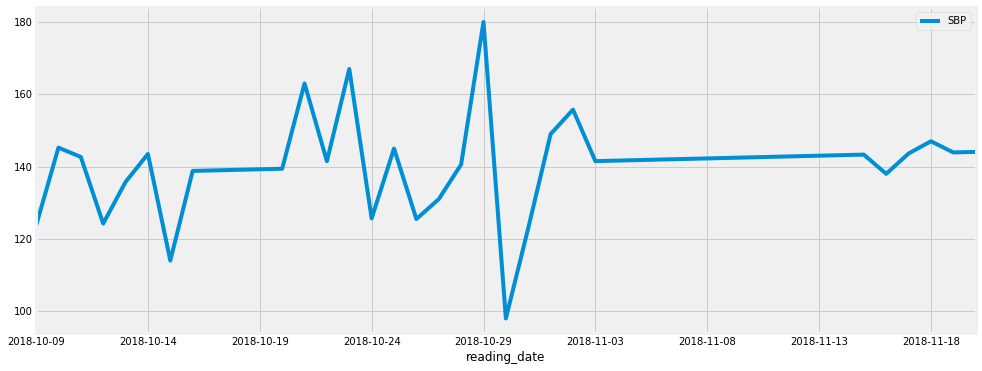

In [5]:
df_vitals_train.plot(figsize=(15, 6))
plt.show()

In [6]:
# Define the p, d and q parameters to take any value between 0 and 2
p = d = q = range(0, 2)

# Generate all different combinations of p, q and q triplets
pdq = list(itertools.product(p, d, q))

# Generate all different combinations of seasonal p, q and q triplets
seasonal_pdq = [(x[0], x[1], x[2], 12) for x in list(itertools.product(p, d, q))]

print('Examples of parameter combinations for Seasonal ARIMA...')
print('SARIMAX: {} x {}'.format(pdq[1], seasonal_pdq[1]))
print('SARIMAX: {} x {}'.format(pdq[1], seasonal_pdq[2]))
print('SARIMAX: {} x {}'.format(pdq[2], seasonal_pdq[3]))
print('SARIMAX: {} x {}'.format(pdq[2], seasonal_pdq[4]))

Examples of parameter combinations for Seasonal ARIMA...
SARIMAX: (0, 0, 1) x (0, 0, 1, 12)
SARIMAX: (0, 0, 1) x (0, 1, 0, 12)
SARIMAX: (0, 1, 0) x (0, 1, 1, 12)
SARIMAX: (0, 1, 0) x (1, 0, 0, 12)


In [7]:
warnings.filterwarnings("ignore") # specify to ignore warning messages

ARIMA_gridsearch_stats = pd.DataFrame(columns = ['patient_uuid','p','d','q','P','D','Q','S','AIC'])

for patient_uuid in df_vitals_sbp_extended['patient_uuid'].unique():
    print(str(currloop) + ' out of ' + str(loopcount) + ', patient_uuid = ' + str(patient_uuid) )
    currloop = currloop + 1
    df_vitals_subset = df_vitals_sbp_extended[df_vitals_sbp_extended['patient_uuid'] == patient_uuid]
    for batch in df_vitals_subset['batch'].unique():
        df_vitals_subset_batch = df_vitals_subset[df_vitals_subset['batch'] == batch]
        if df_vitals_subset_batch.shape[0] > 30:

for param in pdq:
    for param_seasonal in seasonal_pdq:
        try:
            mod = sm.tsa.statespace.SARIMAX(df_vitals_train,
                                            order=param,
                                            seasonal_order=param_seasonal,
                                            enforce_stationarity=False,
                                            enforce_invertibility=False)

            results = mod.fit()
            
            ARIMA_gridsearch_stats.loc[len(ARIMA_gridsearch_stats)] = [param[0],param[1],param[2],param_seasonal[0],param_seasonal[1],param_seasonal[2],param_seasonal[3], results.aic]
            #print('ARIMA{}x{}12 - AIC:{}'.format(param, param_seasonal, results.aic))
        except:
            continue
print('ARIMA grid search completed')

ARIMA grid search completed


In [8]:
ARIMA_gridsearch_stats.head(5)

,p,d,q,P,D,Q,S,AIC
0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,537.119808
1,0.0,0.0,0.0,0.0,0.0,1.0,12.0,1626.427979
2,0.0,0.0,0.0,0.0,1.0,0.0,12.0,262.738838
3,0.0,0.0,0.0,1.0,0.0,0.0,12.0,276.522173
4,0.0,0.0,0.0,1.0,0.0,1.0,12.0,255.579648


In [9]:
ARIMA_gridsearch_stats_min = ARIMA_gridsearch_stats[ARIMA_gridsearch_stats.AIC == ARIMA_gridsearch_stats.AIC.min()]

In [10]:
ARIMA_gridsearch_stats_min

,p,d,q,P,D,Q,S,AIC
47,1.0,1.0,1.0,1.0,1.0,0.0,12.0,142.49076


In [11]:
p = int(ARIMA_gridsearch_stats_min['p'].values[0])
d = int(ARIMA_gridsearch_stats_min['d'].values[0])
q = int(ARIMA_gridsearch_stats_min['q'].values[0])
P = int(ARIMA_gridsearch_stats_min['P'].values[0])
D = int(ARIMA_gridsearch_stats_min['D'].values[0])
Q = int(ARIMA_gridsearch_stats_min['Q'].values[0])
S = int(ARIMA_gridsearch_stats_min['S'].values[0])


mod = sm.tsa.statespace.SARIMAX(df_vitals_train,
                                order=(p, d, q),
                                seasonal_order=(P, D, Q, S),
                                enforce_stationarity=False,
                                enforce_invertibility=False)

results = mod.fit()

print(results.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.0679      0.446     -0.152      0.879      -0.943       0.807
ma.L1         -1.0000   4011.708     -0.000      1.000   -7863.803    7861.803
ar.S.L12      -0.6581      0.154     -4.263      0.000      -0.961      -0.356
sigma2       139.3981   5.59e+05      0.000      1.000    -1.1e+06     1.1e+06


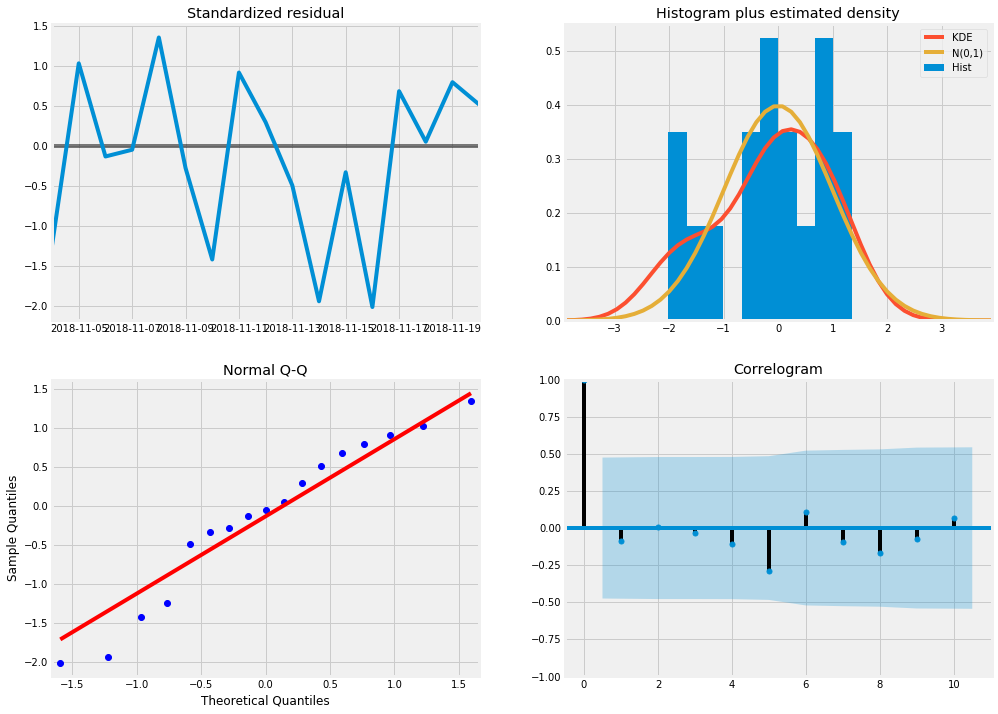

In [12]:
results.plot_diagnostics(figsize=(15, 12))
plt.show()

In [13]:
pred_start_date = list(df_vitals_test.index.values)[0]
pred_start_date

'2018-11-21'

In [14]:
pred_end_date = str((pd.to_datetime(list(df_vitals_test.index.values)[-1]) + timedelta(days=7)).date())
pred_end_date

'2018-12-11'

In [15]:
results.get_prediction(start=pd.to_datetime(pred_start_date), dynamic=False).predicted_mean

2018-11-21    144.774166
Freq: D, dtype: float64

In [16]:
pred = results.get_prediction(start=pd.to_datetime(pred_start_date),end=pd.to_datetime(pred_end_date) ,dynamic=False)
pred_df = pd.DataFrame(pred.predicted_mean)
pred_df.columns=['SBP']
#pred_df.index

In [17]:
mape = (np.mean(np.abs(df_vitals_test - pred_df.head(int(df_vitals_test.shape[0])))/np.abs(df_vitals_test))).get_values()

print(mape)

[0.07727147]


In [18]:
pred_df.index = pd.to_datetime(pred_df.index)

pred_df.dtypes

pred_df.head(5)

,SBP
2018-11-21,144.774166
2018-11-22,171.133068
2018-11-23,117.191325
2018-11-24,133.697799
2018-11-25,150.860513


In [19]:
pred_ci = pred.conf_int()

pred_ci.index = pd.to_datetime(pred_ci.index)

In [20]:
pred_ci_lower = pred_ci[['lower SBP']]

pred_ci_upper = pred_ci[['upper SBP']]

pred_ci_lower.rename(columns={'lower SBP':'SBP'},inplace=True)

pred_ci_upper.rename(columns={'upper SBP':'SBP'},inplace=True)

pred_ci_lower.index = pd.to_datetime(pred_ci_lower.index)

pred_ci_lower.dtypes

pred_ci_upper.index = pd.to_datetime(pred_ci_upper.index)

pred_ci_upper.dtypes

df_vitals_test.index = pd.to_datetime(df_vitals_test.index)

df_vitals_train.index = pd.to_datetime(df_vitals_train.index)

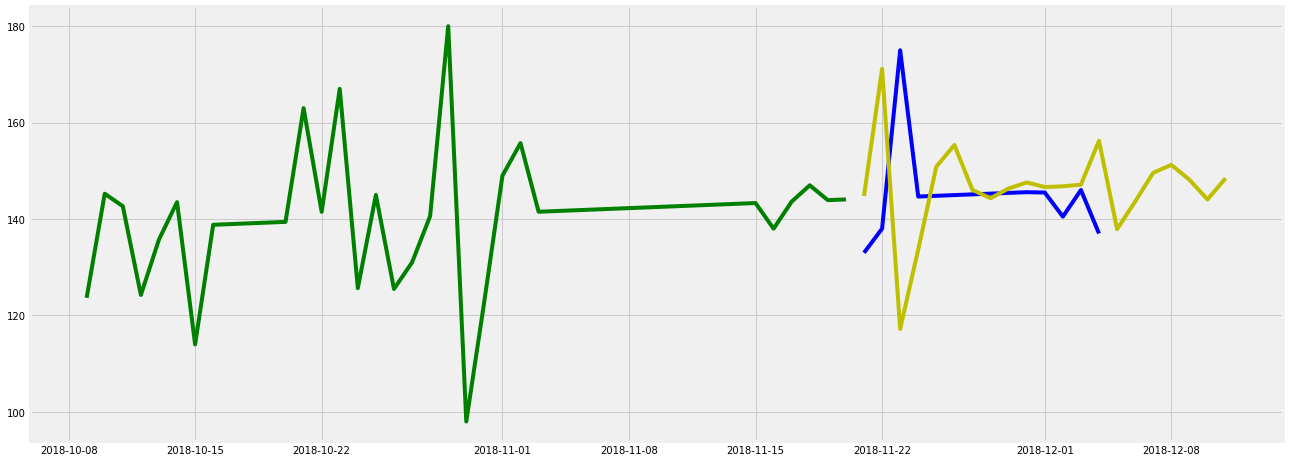

In [35]:
#fig = plt.figure(figsize=(20, 2))

fig, ax = plt.subplots(figsize=(20, 8))
#colors = ['g', 'b', 'y', 'k', 'm']
colors = ['g', 'b', 'y']
index=0
#for frame in [df_vitals_train,df_vitals_test,pred_df, pred_ci_lower, pred_ci_upper]:
for frame in [df_vitals_train,df_vitals_test,pred_df]:
    plt.plot(frame.index, frame['SBP'],color=colors[index])
    index = index + 1

#plt.xlim(0,18000)
#plt.ylim(0,30)
plt.show()

In [39]:
#df_vitals_train

#df_vitals_test

pred_df


,SBP
2018-11-21,144.774166
2018-11-22,171.133068
2018-11-23,117.191325
2018-11-24,133.697799
2018-11-25,150.860513
2018-11-26,155.354279
2018-11-27,146.035856
2018-11-28,144.317452
2018-11-29,146.336291
2018-11-30,147.591974


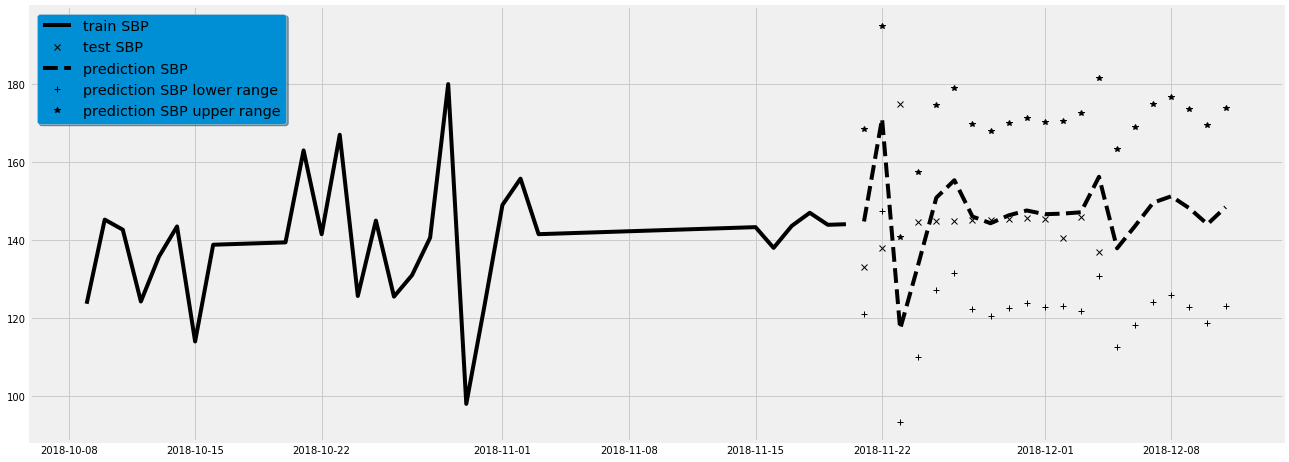

In [36]:
fig, ax = plt.subplots(figsize=(20, 8))

ax.plot(df_vitals_train.index, df_vitals_train['SBP'], 'k', label='train SBP')
ax.plot(df_vitals_test.index, df_vitals_test['SBP'], 'kx', label='test SBP')
ax.plot(pred_df.index, pred_df['SBP'], 'k--', label='prediction SBP')
ax.plot(pred_ci_lower.index, pred_ci_lower['SBP'], 'k+', label='prediction SBP lower range')
ax.plot(pred_ci_upper.index, pred_ci_upper['SBP'], 'k*', label='prediction SBP upper range')

legend = ax.legend(loc='upper left', shadow=True, fontsize='x-large')

# Put a nicer background color on the legend.
legend.get_frame().set_facecolor('C0')

plt.show()